In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C3"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C3_10,27,"[DATA/TRAINING/C3/C3_10/IMG_6627.HEIC, DATA/TR..."
1,C3_11,27,"[DATA/TRAINING/C3/C3_11/IMG_6732.HEIC, DATA/TR..."
2,C3_12,27,"[DATA/TRAINING/C3/C3_12/IMG_6854.HEIC, DATA/TR..."
3,C3_13,30,"[DATA/TRAINING/C3/C3_13/IMG_7002.HEIC, DATA/TR..."
4,C3_14,27,"[DATA/TRAINING/C3/C3_14/IMG_7249.HEIC, DATA/TR..."
5,C3_15,26,"[DATA/TRAINING/C3/C3_15/IMG_7385.HEIC, DATA/TR..."
6,C3_16,26,"[DATA/TRAINING/C3/C3_16/IMG_7516.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7568.HEIC')

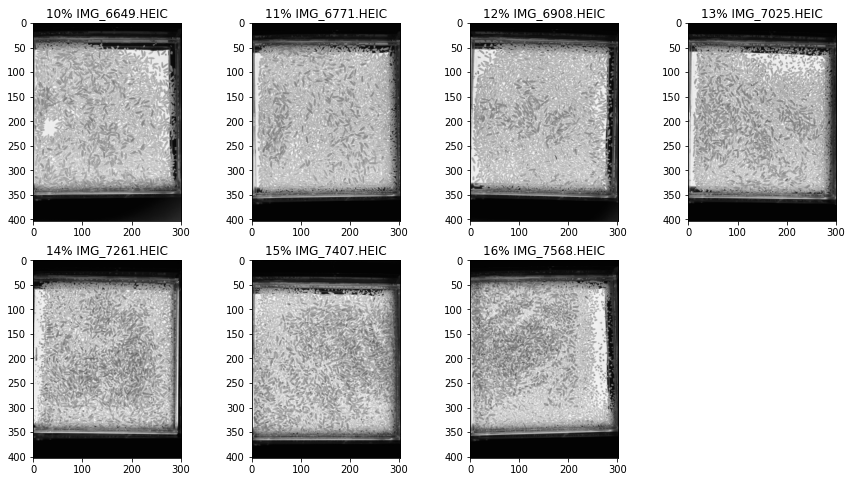

In [7]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [18]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [19]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,416.997378,772.062789,573.141176,760.868851,13.425843,19.168445,15.817367,18.986687,0.228522,0.140485,...,0.007621,0.005259,0.005294,0.005368,3,120,90,3,IMG_6627.HEIC,10
1,410.000562,692.593806,508.313819,718.497403,13.019101,17.681333,14.527077,17.869323,0.229508,0.144587,...,0.008336,0.005918,0.005963,0.006044,3,120,90,3,IMG_6628.HEIC,10
2,343.821816,656.533283,524.225770,678.874705,12.270880,17.257294,14.747526,17.451799,0.228881,0.146336,...,0.008428,0.005968,0.006001,0.006093,3,120,90,3,IMG_6629.HEIC,10
3,382.190637,715.725050,552.351914,736.087999,12.932959,17.987725,15.081699,18.266453,0.231304,0.144633,...,0.007855,0.005518,0.005555,0.005630,3,120,90,3,IMG_6630.HEIC,10
4,333.868539,626.557360,484.740990,640.006704,11.989888,16.797186,14.222409,16.918799,0.225022,0.144162,...,0.008046,0.005771,0.005807,0.005893,3,120,90,3,IMG_6631.HEIC,10
5,334.066573,576.713814,445.876284,568.454159,12.218446,16.578793,14.030159,16.360495,0.215587,0.145949,...,0.008046,0.005751,0.005788,0.005879,3,120,90,3,IMG_6632.HEIC,10
6,643.730712,963.667831,527.068441,954.272590,14.414045,19.740534,15.207563,19.565952,0.219893,0.138711,...,0.007681,0.005405,0.005499,0.005525,3,120,90,3,IMG_6633.HEIC,10
7,366.833427,605.808233,458.844538,606.990841,13.045599,17.371447,14.615780,17.279766,0.207225,0.137517,...,0.007743,0.005524,0.005567,0.005652,3,120,90,3,IMG_6634.HEIC,10
8,371.350749,711.741007,575.942764,713.052497,12.927903,18.014257,15.545565,17.976678,0.215702,0.140193,...,0.008007,0.005743,0.005773,0.005864,3,120,90,3,IMG_6635.HEIC,10
9,373.572566,657.356907,504.531933,676.498442,12.825375,17.485507,14.763119,17.728354,0.220515,0.139858,...,0.007672,0.005419,0.005453,0.005518,3,120,90,3,IMG_6636.HEIC,10


# Classification

In [183]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [184]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [185]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [186]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [187]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [188]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.894737,0.916667,0.904762,0.910675,GLCM,C3,RF_C,20,806,604,3
1,2,0.736842,0.726190,0.738095,0.732094,GLCM,C3,RF_C,20,806,604,3
2,3,0.736842,0.833333,0.714286,0.769231,GLCM,C3,RF_C,20,806,604,3
3,4,0.789474,0.773810,0.785714,0.779716,GLCM,C3,RF_C,20,806,604,3
4,5,0.789474,0.871429,0.761905,0.812995,GLCM,C3,RF_C,20,806,604,3
5,6,0.736842,0.723810,0.690476,0.706750,GLCM,C3,RF_C,20,806,604,3
6,7,0.684211,0.676190,0.666667,0.671395,GLCM,C3,RF_C,20,806,604,3
7,8,0.684211,0.726190,0.690476,0.707883,GLCM,C3,RF_C,20,806,604,3
8,9,0.947368,0.952381,0.952381,0.952381,GLCM,C3,RF_C,20,806,604,3
9,10,0.894737,0.916667,0.904762,0.910675,GLCM,C3,RF_C,20,806,604,3


In [189]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C3,RF_C,0.789474,0.780952,0.79538,0.811667


### MLP Classifier

In [190]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [191]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [192]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.847619,0.809524,0.828134,GLCM,C3,MLP_C,20,806,604,3
1,2,0.789474,0.809524,0.785714,0.797441,GLCM,C3,MLP_C,20,806,604,3
2,3,0.526316,0.557143,0.523810,0.539962,GLCM,C3,MLP_C,20,806,604,3
3,4,0.736842,0.785714,0.738095,0.761161,GLCM,C3,MLP_C,20,806,604,3
4,5,0.631579,0.700000,0.642857,0.670213,GLCM,C3,MLP_C,20,806,604,3
5,6,0.684211,0.823129,0.666667,0.736682,GLCM,C3,MLP_C,20,806,604,3
6,7,0.526316,0.630952,0.500000,0.557895,GLCM,C3,MLP_C,20,806,604,3
7,8,0.684211,0.761905,0.666667,0.711111,GLCM,C3,MLP_C,20,806,604,3
8,9,0.421053,0.476190,0.452381,0.463980,GLCM,C3,MLP_C,20,806,604,3
9,10,0.736842,0.811905,0.738095,0.773243,GLCM,C3,MLP_C,20,806,604,3


In [193]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C3,MLP_C,0.652632,0.652381,0.683982,0.720408


### XGBoost Classifier

In [194]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [195]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.857143,0.857143,0.857143,GLCM,C3,XGB_C,20,806,604,3
1,2,0.736842,0.845238,0.714286,0.774264,GLCM,C3,XGB_C,20,806,604,3
2,3,0.789474,0.866667,0.809524,0.837121,GLCM,C3,XGB_C,20,806,604,3
3,4,0.789474,0.809524,0.785714,0.797441,GLCM,C3,XGB_C,20,806,604,3
4,5,0.894737,0.916667,0.904762,0.910675,GLCM,C3,XGB_C,20,806,604,3
5,6,0.578947,0.488095,0.523810,0.505322,GLCM,C3,XGB_C,20,806,604,3
6,7,0.789474,0.845238,0.809524,0.826996,GLCM,C3,XGB_C,20,806,604,3
7,8,0.789474,0.845238,0.785714,0.814390,GLCM,C3,XGB_C,20,806,604,3
8,9,0.842105,0.857143,0.833333,0.845070,GLCM,C3,XGB_C,20,806,604,3
9,10,0.736842,0.809524,0.761905,0.784993,GLCM,C3,XGB_C,20,806,604,3


In [196]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C3,XGB_C,0.778947,0.778571,0.795342,0.814048


# External validation

In [197]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C3_10,5,"[DATA/TEST/C3/C3_10/IMG_6622.HEIC, DATA/TEST/C..."
1,C3_11,5,"[DATA/TEST/C3/C3_11/IMG_6717.HEIC, DATA/TEST/C..."
2,C3_12,5,"[DATA/TEST/C3/C3_12/IMG_6845.HEIC, DATA/TEST/C..."
3,C3_13,5,"[DATA/TEST/C3/C3_13/IMG_6987.HEIC, DATA/TEST/C..."
4,C3_14,5,"[DATA/TEST/C3/C3_14/IMG_7239.HEIC, DATA/TEST/C..."
5,C3_15,5,"[DATA/TEST/C3/C3_15/IMG_7376.HEIC, DATA/TEST/C..."
6,C3_16,5,"[DATA/TEST/C3/C3_16/IMG_7506.HEIC, DATA/TEST/C..."


In [198]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [199]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [200]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,232.527392,395.182866,246.340622,397.450730,7.310737,10.464339,7.915226,10.549126,0.378777,0.307590,...,0.009275,0.008801,0.008981,0.008804,20,806,604,3,IMG_6622.HEIC,10
1,234.781197,407.894293,260.695428,407.122524,7.360801,10.641632,8.180291,10.691458,0.375852,0.302745,...,0.009969,0.009442,0.009656,0.009431,20,806,604,3,IMG_6623.HEIC,10
2,227.053640,378.043066,238.357661,394.853684,7.103498,10.058904,7.681354,10.437595,0.391432,0.319233,...,0.009394,0.008899,0.009024,0.008907,20,806,604,3,IMG_6624.HEIC,10
3,230.558671,398.335018,247.501209,396.539730,7.299010,10.572082,7.955251,10.562939,0.376736,0.300386,...,0.009642,0.009124,0.009224,0.009131,20,806,604,3,IMG_6625.HEIC,10
4,230.025970,384.173070,238.703832,379.185369,7.739071,10.808762,7.996230,10.657120,0.345484,0.276734,...,0.008973,0.008519,0.008622,0.008537,20,806,604,3,IMG_6626.HEIC,10
0,231.649581,393.792252,261.698246,407.505201,7.708315,10.837428,8.365289,11.116861,0.348959,0.286241,...,0.017186,0.016583,0.016714,0.016589,20,806,604,3,IMG_6717.HEIC,11
1,225.109934,373.240104,249.175863,401.749262,7.576505,10.446844,8.035967,10.977106,0.355474,0.293797,...,0.017059,0.016467,0.016600,0.016464,20,806,604,3,IMG_6721.HEIC,11
2,236.070880,384.804384,241.149743,386.307535,7.737555,10.624278,7.898075,10.684429,0.353799,0.290492,...,0.016109,0.015536,0.015693,0.015534,20,806,604,3,IMG_6724.HEIC,11
3,200.626983,351.153782,252.545911,388.065589,6.921005,9.840563,7.938417,10.557008,0.383191,0.316707,...,0.016999,0.016369,0.016511,0.016366,20,806,604,3,IMG_6728.HEIC,11
4,225.941220,389.380713,259.684787,401.269940,7.413347,10.529726,8.077263,10.693951,0.370701,0.303483,...,0.016312,0.015714,0.015871,0.015731,20,806,604,3,IMG_6731.HEIC,11


In [201]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [202]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [203]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [204]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [205]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      1.00      0.67         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.40      0.40      0.40         5
     Class 4       0.20      0.20      0.20         5
     Class 5       0.00      0.00      0.00         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.57        35
   macro avg       0.50      0.57      0.52        35
weighted avg       0.50      0.57      0.52        35



## MLP

In [206]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [207]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.33      0.20      0.25         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.67      0.40      0.50         5
     Class 5       0.20      0.20      0.20         5
     Class 6       0.45      1.00      0.62         5

    accuracy                           0.51        35
   macro avg       0.49      0.51      0.48        35
weighted avg       0.49      0.51      0.48        35



## XGBC

In [208]:
y_pred = modelXGBC.predict(X_test_scale) 

In [209]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.56      1.00      0.71         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.33      0.20      0.25         5
     Class 5       1.00      0.20      0.33         5
     Class 6       0.50      1.00      0.67         5

    accuracy                           0.54        35
   macro avg       0.56      0.54      0.49        35
weighted avg       0.56      0.54      0.49        35

